### Body Fat Prediction - 추가 분석 : 줄자로 잴 수 있는 변수만으로 체지방 예측하기
### 학습 내용
 * 기본 분석([01_09_bodyFatPredict](https://ldjwj.github.io/dataAnalysis/01_09_bodyFatPredict.html))에서 한 걸음 더 : **정답을 미리 알려 주는 변수(Density)** 를 왜 빼야 하는지 이해하기
 * 변수 1~3개 조합을 **교차검증(MAE)** 으로 비교해, 집에서도 계산할 수 있는 **간단한 선형식** 만들기
 * 이상치 처리, 전체 변수 모델과의 비교, **잔차(오차) 분석**

### 내용
 * 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * 1. 데이터 준비 (단위 변환)
 * 2. Density는 왜 빼야 할까? - Siri 공식과 산점도
 * 3. 이상치 확인과 처리
 * 4. 변수 1~3개 조합 비교 (교차검증)
 * 5. 간단한 체지방 계산식
 * 6. 전체 변수 모델과 비교
 * 7. 잔차(오차) 분석
 * 8. 정리

### 0. 기본 분석 돌아보기 - 무엇을 보완할까?
 * **기본 분석 내용** : `Age, Weight, Height, Neck, Chest, Hip` 6개 변수로 70% / 30% 한 번 나누어(random_state=0) 학습
   * 의사결정트리 : 학습 R² **1.0**, 평가 R² **0.32** → 심한 과적합
   * 랜덤포레스트 : 평가 R² **0.575**, `max_depth=6` 최종 모델의 RMSE **5.09**(%p)
 * **보완할 점**
   * 체지방과 가장 관련이 클 것 같은 **복부 둘레(Abdomen)** 가 변수에서 빠져 있다.
   * 평가 데이터를 **한 번만** 나누어 결과가 나누는 방법에 따라 달라질 수 있다. → **교차검증** 필요
   * `max_depth` 반복문 안의 mse/rmse는 **이전에 만든 `pred`를 그대로 사용**해 매번 같은 값(5.086)이 출력되었다.
   * `BodyFat = 0`, 키 29.5인치(약 75cm) 같은 **이상한 값**을 확인하지 않았다.
   * `Density`(체밀도)는 데이터에 있지만 사용 여부를 설명하지 않았다. → 2장에서 확인
 * 이번 목표 : **줄자와 체중계로 잴 수 있는 값**만으로, 사람이 직접 계산할 수 있는 **짧은 식**을 만든다.

### 필수 라이브러리 불러오기

In [1]:
import warnings
from itertools import combinations
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings('ignore')

# 한글 폰트 설정
# - koreanize-matplotlib이 설치되어 있으면 OS와 상관없이 나눔고딕을 사용 (pip install koreanize-matplotlib)
# - 없으면 OS에 맞는 기본 한글 폰트를 사용
try:
    import koreanize_matplotlib
except ImportError:
    import platform
    plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic',
                                   'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', font=plt.rcParams['font.family'])

### 1. 데이터 준비
 * 원본 단위 : 체중 **파운드(lbs)**, 키 **인치(inch)**, 둘레는 모두 **cm**
 * 계산식을 쉽게 쓰기 위해 체중은 **kg**, 키는 **cm**로 바꾼다.

In [2]:
raw = pd.read_csv("./data/bodyFat/bodyfat.csv")
raw['Weight'] = (raw['Weight'] * 0.4536).round(1)   # lbs → kg
raw['Height'] = (raw['Height'] * 2.54).round(1)     # inch → cm

name_kor = {'Age': '나이', 'Weight': '체중(kg)', 'Height': '키(cm)', 'Neck': '목', 'Chest': '가슴',
            'Abdomen': '복부', 'Hip': '엉덩이', 'Thigh': '허벅지', 'Knee': '무릎', 'Ankle': '발목',
            'Biceps': '이두근', 'Forearm': '팔뚝', 'Wrist': '손목'}
print(raw.shape)
raw[['BodyFat', 'Weight', 'Height', 'Abdomen', 'Density']].describe().round(2)

(252, 15)


,BodyFat,Weight,Height,Abdomen,Density
count,252.00,252.00,252.00,252.00,252.00
mean,19.15,81.16,178.18,92.56,1.06
std,8.37,13.33,9.31,10.78,0.02
min,0.00,53.80,74.90,69.40,1.00
25%,12.48,72.10,173.40,84.57,1.04
50%,19.20,80.05,177.80,90.95,1.05
75%,25.30,89.40,183.50,99.32,1.07
max,47.50,164.70,197.50,148.10,1.11


* 한줄 확인 : 체중 53.8~164.7kg, 키는 최솟값이 **74.9cm**(29.5인치)로 성인 남성의 키로 보기 어렵고, 체지방 최솟값은 **0%** 이다. → 3장에서 처리

### 2. Density는 왜 빼야 할까? - Siri 공식과 산점도
 * 이 데이터의 `BodyFat`은 줄자로 잰 값이 아니라, **수중 체중 측정으로 구한 체밀도(Density)** 를 **Siri 공식**에 넣어 계산한 값이다.
   * **Siri 공식 : BodyFat(%) = 495 / Density − 450**
 * 즉 Density를 알면 BodyFat을 거의 그대로 계산할 수 있다. → 모델에 넣으면 **정답을 알려 주는 것(데이터 누수)** 과 같다.
 * 또 Density는 물속에서 몸무게를 재는 특수 장비가 필요해, "줄자로 간단히 예측"이라는 목표와도 맞지 않는다.

Density와 BodyFat의 상관계수 : -0.988
Siri 공식과 1%p 이내로 일치하는 행 : 247 / 252


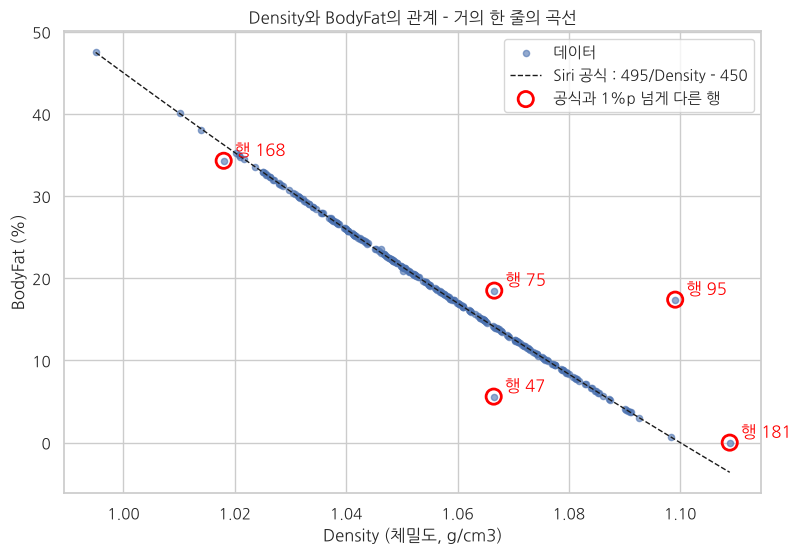

,Density,BodyFat,Siri계산,차이,Weight,Height,Abdomen
47,1.07,5.6,14.14,-8.54,67.4,181.0,79.5
75,1.07,18.5,14.09,4.41,67.2,171.4,81.8
95,1.10,17.4,0.37,17.03,101.8,197.5,99.2
168,1.02,34.3,36.25,-1.95,103.5,176.5,115.9
181,1.11,0.0,-3.61,3.61,53.8,172.7,69.4


In [3]:
raw['Siri계산'] = 495 / raw['Density'] - 450
raw['차이'] = raw['BodyFat'] - raw['Siri계산']

print('Density와 BodyFat의 상관계수 :', round(raw['Density'].corr(raw['BodyFat']), 3))
print('Siri 공식과 1%p 이내로 일치하는 행 :', (raw['차이'].abs() <= 1).sum(), '/', len(raw))

d = np.linspace(raw['Density'].min(), raw['Density'].max(), 100)
mismatch = raw['차이'].abs() > 1

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(raw['Density'], raw['BodyFat'], s=20, alpha=0.6, label='데이터')
ax.plot(d, 495 / d - 450, 'k--', lw=1, label='Siri 공식 : 495/Density - 450')
ax.scatter(raw.loc[mismatch, 'Density'], raw.loc[mismatch, 'BodyFat'], s=120,
           facecolors='none', edgecolors='red', lw=2, label='공식과 1%p 넘게 다른 행')
for i, r in raw[mismatch].iterrows():
    ax.annotate(f'행 {i}', (r['Density'], r['BodyFat']), xytext=(8, 4), textcoords='offset points', color='red')
ax.set_xlabel('Density (체밀도, g/cm3)')
ax.set_ylabel('BodyFat (%)')
ax.set_title('Density와 BodyFat의 관계 - 거의 한 줄의 곡선')
ax.legend()
plt.show()

raw.loc[mismatch, ['Density', 'BodyFat', 'Siri계산', '차이', 'Weight', 'Height', 'Abdomen']].round(2)

* 한줄 확인
   * Density와 BodyFat의 상관계수는 **-0.988**, 252명 중 **247명**이 Siri 공식과 1%p 이내로 일치한다. → BodyFat은 사실상 Density로 **계산된 값**
   * 공식과 1%p 넘게 다른 **5개 행**은 입력 오류일 가능성이 높다.
     * 행 95 : 공식으로는 0.37%인데 17.4%로 기록 (차이 **17.03**%p)
     * 행 47 : 차이 -8.54%p, 행 75 : 차이 4.41%p
     * 행 181 : 공식으로는 **-3.61%**(불가능한 값)이고, 기록은 0.0%
     * 행 168 : 차이 -1.95%p로 작아 그대로 사용

In [4]:
# 참고 : Density 하나만 넣은 선형 회귀의 교차검증 MAE
kf = KFold(n_splits=5, shuffle=True, random_state=42)
mae_density = -cross_val_score(LinearRegression(), raw[['Density']], raw['BodyFat'],
                               cv=kf, scoring='neg_mean_absolute_error').mean()
print(f'Density 하나로 예측한 MAE : {mae_density:.2f}%p')

Density 하나로 예측한 MAE : 0.38%p


* 한줄 확인 : Density 하나만으로 MAE **0.38%p** → 거의 정답을 맞힌다. 줄자 모델과 비교하는 의미가 없으므로 **Density는 입력 변수에서 제외**한다.

### 3. 이상치 확인과 처리
 * 2장의 **Siri 공식과 맞지 않는 행** 외에, 사람의 신체로 보기 어려운 값을 확인한다.

In [5]:
raw['BMI'] = raw['Weight'] / (raw['Height'] / 100) ** 2

check = raw[(raw['BodyFat'] < 3) | (raw['Height'] < 150) | (raw['BMI'] > 40)]
check[['BodyFat', 'Density', 'Siri계산', 'Weight', 'Height', 'BMI', 'Abdomen']].round(2)

,BodyFat,Density,Siri계산,Weight,Height,BMI,Abdomen
38,35.2,1.02,35.20,164.7,183.5,48.91,148.1
41,32.9,1.02,32.93,93.0,74.9,165.78,104.3
171,0.7,1.10,0.70,57.0,166.4,20.59,75.0
181,0.0,1.11,-3.61,53.8,172.7,18.04,69.4


* 한줄 확인
   * **행 41** : 키 **74.9cm**, BMI **165.8** → 키 입력 오류로 판단해 제거 (체중 93kg인 사람이 75cm일 수 없음)
   * **행 181** : 체지방 **0%**, Siri 계산값 -3.61% → 사람의 체지방은 0%가 될 수 없으므로 제거
   * **행 171** : 체지방 0.7%로 매우 낮지만 Siri 공식과 일치(0.70) → 실제 측정값으로 보고 **유지**
   * **행 38** : 체중 164.7kg, BMI 48.9로 매우 크지만 Siri 공식과 일치 → 실제 사람으로 보고 **유지** (7장에서 오차 확인)
   * 2장의 Siri 공식 불일치 행 중 차이가 큰 **행 47, 75, 95**도 제거한다.

In [6]:
drop_rows = [41, 47, 75, 95, 181]   # 키 오류 1개 + Siri 공식 불일치 3개 + 체지방 0%
df = raw.drop(index=drop_rows).copy()
print('제거한 행 :', drop_rows)
print('처리 전', raw.shape[0], '명 → 처리 후', df.shape[0], '명')

제거한 행 : [41, 47, 75, 95, 181]
처리 전 252 명 → 처리 후 247 명


### 4. 변수 1~3개 조합 비교 (교차검증)
 * 후보 변수 13개 : 나이 + 체중 + 키 + 둘레 10개 (모두 줄자·체중계로 잴 수 있거나 알고 있는 값, **Density 제외**)
 * 1개 13가지, 2개 78가지, 3개 286가지 → **총 377개 조합**을 선형 회귀로 모두 비교
 * 평가 : **5-fold × 3회 반복 교차검증**(RepeatedKFold, random_state=42)의 **MAE(%p)**
   * MAE 3.5 = "평균적으로 실제 체지방과 3.5%p 차이"

In [7]:
candidates = ['Age', 'Weight', 'Height', 'Neck', 'Chest', 'Abdomen', 'Hip',
              'Thigh', 'Knee', 'Ankle', 'Biceps', 'Forearm', 'Wrist']
y = df['BodyFat']
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

def cv_mae(model, cols):
    return -cross_val_score(model, df[list(cols)], y, cv=rkf, scoring='neg_mean_absolute_error').mean()

rows = []
for k in [1, 2, 3]:
    for cols in combinations(candidates, k):
        rows.append({'변수 개수': k, '변수': ' + '.join(name_kor[c] for c in cols),
                     'cols': cols, 'MAE': cv_mae(LinearRegression(), cols)})
combo = pd.DataFrame(rows).sort_values('MAE')
print('비교한 조합 수 :', len(combo))

# 변수 개수별 상위 5개 조합
top = combo.groupby('변수 개수').head(5).sort_values(['변수 개수', 'MAE'])
top[['변수 개수', '변수', 'MAE']].round(3)

비교한 조합 수 : 377


,변수 개수,변수,MAE
5,1,복부,3.934
4,1,가슴,4.885
6,1,엉덩이,5.303
1,1,체중(kg),5.351
7,1,허벅지,5.652
28,2,체중(kg) + 복부,3.650
69,2,복부 + 손목,3.755
47,2,목 + 복부,3.760
63,2,복부 + 엉덩이,3.762
65,2,복부 + 무릎,3.826


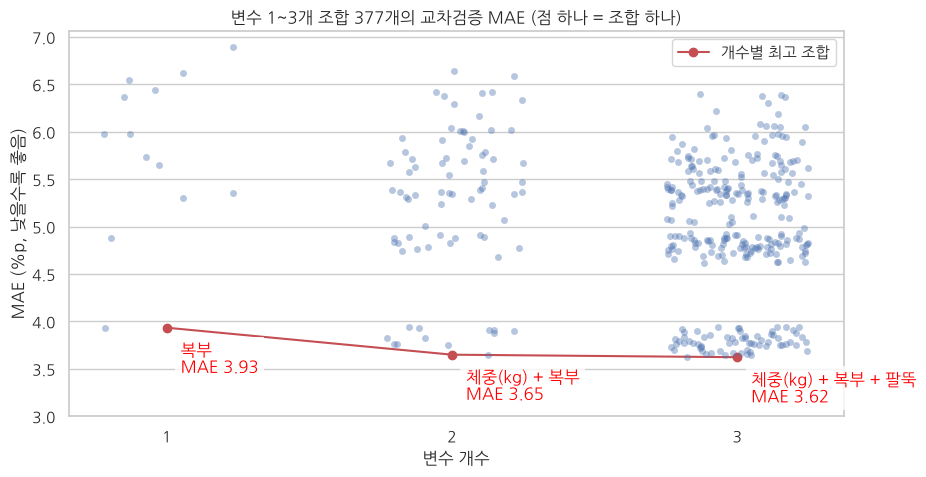

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.stripplot(data=combo, x='변수 개수', y='MAE', alpha=0.4, jitter=0.25, ax=ax)
best_k = combo.groupby('변수 개수')['MAE'].min()
ax.plot(range(3), best_k.values, 'r-o', label='개수별 최고 조합')
for i, (v, name) in enumerate(zip(best_k.values, combo.groupby('변수 개수').head(1).sort_values('변수 개수')['변수'])):
    ax.annotate(f'{name}\nMAE {v:.2f}', (i, v), xytext=(10, -32), textcoords='offset points', color='red',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_ylim(3.0, None)
ax.set_title('변수 1~3개 조합 377개의 교차검증 MAE (점 하나 = 조합 하나)')
ax.set_ylabel('MAE (%p, 낮을수록 좋음)')
ax.legend()
plt.show()

* 한줄 확인
   * 1개 변수 중 최고는 **복부(MAE 3.934)**, 2위 가슴(4.885)과도 차이가 크다. → 체지방 예측에 **복부 둘레가 핵심**
   * 2개 변수 최고는 **체중 + 복부(3.650)**, 3개 변수 최고는 **체중 + 복부 + 팔뚝(3.623)**
   * 2개·3개 변수의 상위 5개 조합에는 **모두 복부가 포함**되어 있다.
   * 그래프의 점들이 두 무리로 뚜렷하게 나뉜다. 아래쪽 무리(MAE 약 3.6~3.9)는 복부가 들어간 조합, 위쪽 무리(약 4.6 이상)는 복부가 없는 조합이다.
   * 2개 → 3개로 늘려도 MAE는 **0.027%p만** 줄어든다. → **2개 변수 식(체중 + 복부)** 이면 충분하다.

### 5. 간단한 체지방 계산식
 * 1~3개 변수의 **최고 조합**을 전체 데이터로 학습해 계산식을 만든다.

In [9]:
formulas = []
for k in [1, 2, 3]:
    cols = list(combo[combo['변수 개수'] == k].iloc[0]['cols'])
    lr = LinearRegression().fit(df[cols], y)
    terms = ' '.join(f'{b:+.3f} × {name_kor[c]}' for c, b in zip(cols, lr.coef_))
    formulas.append({'변수 개수': k, '계산식': f'체지방(%) = {lr.intercept_:.2f} {terms}',
                     '교차검증 MAE': cv_mae(LinearRegression(), cols)})
    if k == 2:
        lr2, cols2 = lr, cols

pd.set_option('display.max_colwidth', None)
pd.DataFrame(formulas).round(3)

,변수 개수,계산식,교차검증 MAE
0,1,체지방(%) = -38.79 +0.626 × 복부,3.934
1,2,체지방(%) = -45.26 -0.323 × 체중(kg) +0.979 × 복부,3.650
2,3,체지방(%) = -52.68 -0.365 × 체중(kg) +0.996 × 복부 +0.326 × 팔뚝,3.623


* 한줄 확인
   * **추천 식 (2개 변수) : 체지방(%) = -45.26 − 0.323 × 체중(kg) + 0.979 × 복부 둘레(cm)**
   * 복부 둘레가 **1cm** 늘면 체지방이 약 **0.98%p** 증가
   * 체중의 계수가 **음수(-0.323)** 인 이유 : 복부 둘레가 같다면 체중이 무거운 사람은 **근육·골격이 큰 사람**일 가능성이 높아 체지방률이 낮다.
     * 체중 하나만 보면 체지방과 양의 관계지만, 복부 둘레와 함께 넣으면 의미가 바뀐다.
   * 1개 변수 식 : 체지방(%) = -38.79 + 0.626 × 복부 → 복부 둘레만 알아도 MAE 3.93%p

In [10]:
# 계산식 사용 예 : 위 2개 변수 식에 값 넣어 보기
example = df[cols2].median().round(1)
print('예시 입력 (데이터 중앙값) :', {name_kor[c]: float(v) for c, v in example.items()})
print(f'예측 체지방 : {lr2.predict(example.to_frame().T)[0]:.1f}%')

예시 입력 (데이터 중앙값) : {'체중(kg)': 80.2, '복부': 91.0}
예측 체지방 : 17.9%


* 한줄 확인 : 체중 80.2kg, 복부 둘레 91.0cm(데이터 중앙값)인 사람의 예측 체지방은 **17.9%**

### 6. 전체 변수 모델과 비교
 * 같은 5-fold × 3회 교차검증으로 비교
   * **기준** : 모든 사람을 평균 체지방으로 예측
   * **기본 분석 변수 6개** (Age, Weight, Height, Neck, Chest, Hip) - 선형 회귀 / 랜덤포레스트
   * **13개 전체 변수** - 선형 회귀 / 랜덤포레스트

In [11]:
from sklearn.dummy import DummyRegressor

orig6 = ['Age', 'Weight', 'Height', 'Neck', 'Chest', 'Hip']
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=2)
best = {k: list(combo[combo['변수 개수'] == k].iloc[0]['cols']) for k in [1, 2, 3]}

compare = [
    ('기준 (평균 예측)',              DummyRegressor(), candidates),
    ('기본 분석 6개 - 랜덤포레스트',    rf, orig6),
    ('기본 분석 6개 - 선형 회귀',      LinearRegression(), orig6),
    ('1개 변수 식',                  LinearRegression(), best[1]),
    ('2개 변수 식',                  LinearRegression(), best[2]),
    ('3개 변수 식',                  LinearRegression(), best[3]),
    ('13개 전체 - 랜덤포레스트',       rf, candidates),
    ('13개 전체 - 선형 회귀',         LinearRegression(), candidates),
]
cmp_df = pd.DataFrame([{'모델': n, '변수 수': len(c), 'MAE': cv_mae(m, c)} for n, m, c in compare]).round(3)
cmp_df

,모델,변수 수,MAE
0,기준 (평균 예측),13,6.846
1,기본 분석 6개 - 랜덤포레스트,6,4.689
2,기본 분석 6개 - 선형 회귀,6,4.489
3,1개 변수 식,1,3.934
4,2개 변수 식,2,3.650
5,3개 변수 식,3,3.623
6,13개 전체 - 랜덤포레스트,13,3.866
7,13개 전체 - 선형 회귀,13,3.732


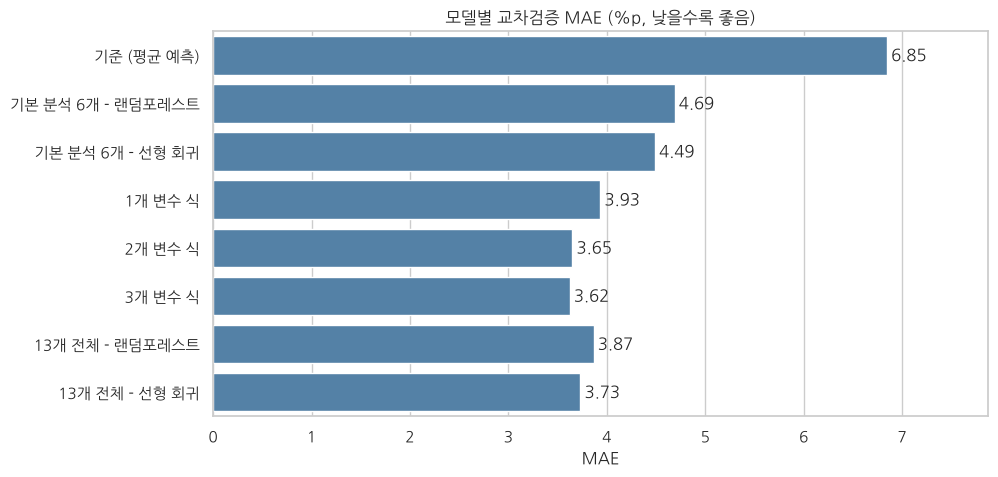

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=cmp_df, y='모델', x='MAE', color='steelblue', ax=ax)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3)
ax.set_title('모델별 교차검증 MAE (%p, 낮을수록 좋음)')
ax.set_ylabel('')
ax.set_xlim(0, cmp_df['MAE'].max() * 1.15)
plt.show()

* 한줄 확인
   * 기준(평균 예측) MAE **6.846** → 2개 변수 식 **3.650**으로 오차가 약 47% 줄었다.
   * 기본 분석의 6개 변수(복부 없음)는 랜덤포레스트 **4.689**, 선형 회귀 **4.489**로, **복부 하나만 쓴 식(3.934)보다도 나쁘다.**
   * 13개 전체 변수 모델(선형 회귀 3.732, 랜덤포레스트 3.866)보다 **2개 변수 식(3.650)이 오히려 더 정확**하다.
     * 데이터가 247명으로 적어, 변수가 많으면 서로 비슷한 둘레 변수들 때문에 **과적합**이 생기기 쉽다.
   * 이 데이터에서는 랜덤포레스트보다 **선형 회귀가 더 좋다.** (6개 : 4.689 vs 4.489, 13개 : 3.866 vs 3.732)

### 7. 잔차(오차) 분석
 * **2개 변수 식**의 교차검증 예측값(`cross_val_predict`, 각 사람은 학습에 쓰이지 않은 fold에서 예측)으로 오차를 본다.
 * 잔차 = 실제 − 예측 (양수면 실제보다 낮게 예측)

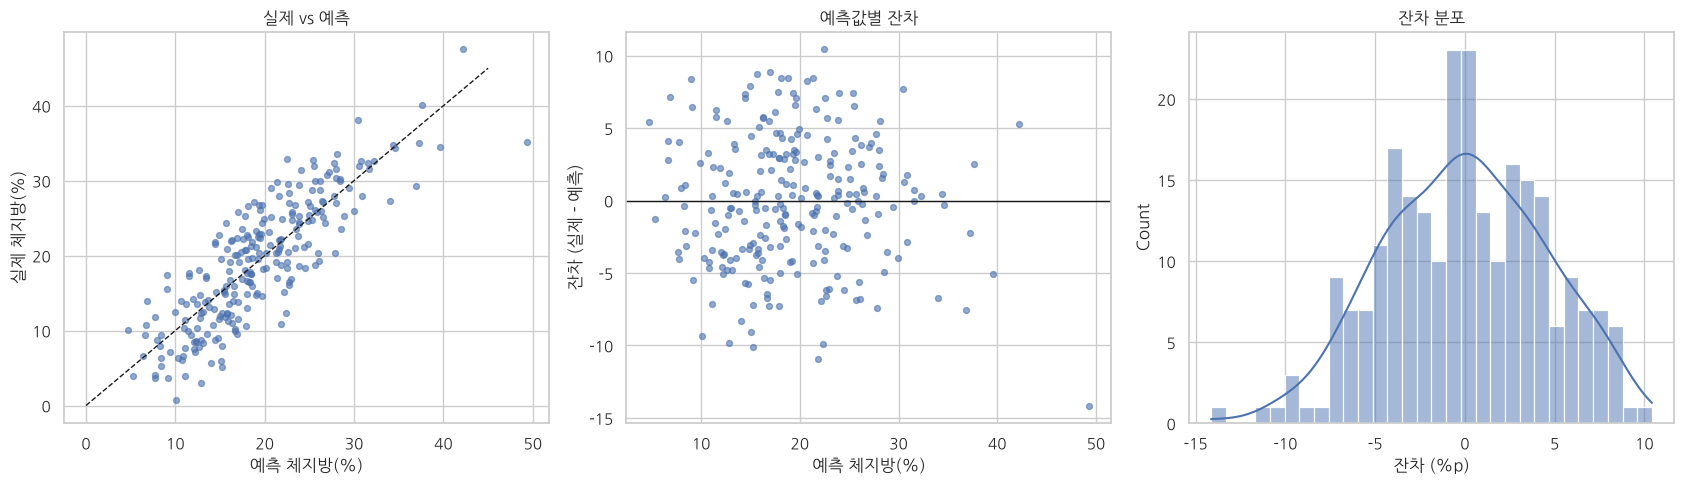

MAE : 3.64%p, 잔차 표준편차 : 4.50%p
오차 3%p 이내 : 44.1%, 5%p 이내 : 71.3%


In [13]:
df['예측'] = cross_val_predict(LinearRegression(), df[cols2], y, cv=kf)
df['잔차'] = df['BodyFat'] - df['예측']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].scatter(df['예측'], df['BodyFat'], s=18, alpha=0.6)
axes[0].plot([0, 45], [0, 45], 'k--', lw=1)
axes[0].set(title='실제 vs 예측', xlabel='예측 체지방(%)', ylabel='실제 체지방(%)')

axes[1].scatter(df['예측'], df['잔차'], s=18, alpha=0.6)
axes[1].axhline(0, color='k', lw=1)
axes[1].set(title='예측값별 잔차', xlabel='예측 체지방(%)', ylabel='잔차 (실제 - 예측)')

sns.histplot(df['잔차'], bins=30, kde=True, ax=axes[2])
axes[2].set(title='잔차 분포', xlabel='잔차 (%p)')
plt.tight_layout()
plt.show()

abs_err = df['잔차'].abs()
print(f'MAE : {abs_err.mean():.2f}%p, 잔차 표준편차 : {df["잔차"].std():.2f}%p')
print(f'오차 3%p 이내 : {(abs_err <= 3).mean() * 100:.1f}%, 5%p 이내 : {(abs_err <= 5).mean() * 100:.1f}%')

* 한줄 확인
   * 교차검증 예측의 MAE **3.64%p**, 잔차 표준편차 **4.50%p**
   * 오차 3%p 이내가 **44.1%**, 5%p 이내가 **71.3%** → 10명 중 약 7명은 ±5%p 안에서 맞힌다.
   * 잔차는 0을 중심으로 대체로 좌우 대칭이며, 오른쪽 아래(예측 약 49%, 잔차 -14.1)에 **행 38(체중 164.7kg)** 이 홀로 떨어져 있다.

In [14]:
# 체지방 구간별 평균 잔차 - 어느 구간에서 치우치게 예측할까?
df['체지방 구간'] = pd.cut(df['BodyFat'], bins=[0, 10, 20, 30, 50])
df.groupby('체지방 구간', observed=True)['잔차'].agg(인원수='count', 평균잔차='mean',
                                                   평균절대오차=lambda s: s.abs().mean()).round(2)

,인원수,평균잔차,평균절대오차
체지방 구간,,,
"(0, 10]",38,-4.27,4.53
"(10, 20]",90,-1.20,3.24
"(20, 30]",95,2.19,3.53
"(30, 50]",24,2.31,4.12


* 한줄 확인
   * 체지방 **10% 이하**인 사람은 평균 잔차 **-4.27** → 실제보다 약 4%p **높게** 예측
   * 체지방 **20% 초과**인 사람은 평균 잔차 **+2.19 ~ +2.31** → 실제보다 약 2%p **낮게** 예측
   * 선형 회귀는 예측값을 평균 쪽으로 끌어당기는 경향이 있어, 아주 마른 사람과 체지방이 많은 사람에서 오차가 커진다. (평균 절대오차 : 10% 이하 4.53, 30% 초과 4.12)

In [15]:
# 오차가 가장 큰 5명
show = ['BodyFat', '예측', '잔차', 'Age'] + cols2 + ['Height', 'BMI']
df.reindex(df['잔차'].abs().sort_values(ascending=False).index)[show].head(5).round(1)

,BodyFat,예측,잔차,Age,Weight,Abdomen,Height,BMI
38,35.2,49.3,-14.1,46,164.7,148.1,183.5,48.9
224,10.9,21.8,-10.9,55,81.5,95.3,174.6,26.7
206,32.9,22.5,10.4,44,75.3,93.9,166.4,27.2
223,5.2,15.3,-10.1,55,64.5,82.8,170.8,22.1
220,12.4,22.3,-9.9,54,69.5,91.8,179.1,21.7


* 한줄 확인
   * 오차 1위는 **행 38**(체중 164.7kg, 복부 148.1cm) : 실제 35.2%를 49.3%로 예측(잔차 -14.1) → 데이터 범위 끝의 사람은 직선 식이 맞지 않는다.
   * 나머지 상위 오차(약 10%p)는 체중·복부 둘레가 평범한 사람들로, 같은 둘레라도 **개인 차이(근육량, 체형)** 가 있음을 보여 준다.
   * 상위 5명은 모두 **44~55세**이다. 나이가 들면 같은 둘레에서도 체성분이 달라질 수 있다.

### 8. 정리
| 질문 | 기본 분석 | 추가 분석 결과 |
|---|---|---|
| Density를 입력에 넣어도 될까? | 사용 여부 설명 없음 | BodyFat = 495/Density − 450(Siri)로 계산된 값. 상관계수 **-0.988**, Density 하나로 MAE **0.38** → **제외** |
| 이상한 값은? | 확인하지 않음 | 키 74.9cm(행 41), 체지방 0%(행 181), Siri 공식 불일치(행 47, 75, 95) → **5개 행 제거**, 247명 사용 |
| 평가 방법 | 70/30 한 번 분할, R² 0.575(RF), RMSE 5.09 | **5-fold × 3회 교차검증 MAE**로 377개 조합 비교 |
| 가장 중요한 변수는? | 복부 둘레를 사용하지 않음 | **복부 둘레** 하나로 MAE 3.934 (2위 가슴 4.885) |
| 간단한 식은? | - | **체지방(%) = -45.26 − 0.323 × 체중(kg) + 0.979 × 복부(cm)**, MAE **3.650** |
| 변수를 많이 쓰면 더 좋을까? | 6개 변수 RF | 13개 전체 선형 회귀 3.732, RF 3.866 → **2개 변수 식이 더 정확** |
| 오차의 특징은? | - | ±5%p 이내 71.3%, 마른 사람(10% 이하)은 약 4.3%p 높게, 20% 초과는 약 2.2~2.3%p 낮게 예측 |

#### 배운 점
 * 타깃을 계산하는 데 쓰인 변수(Density)는 **데이터 누수**이므로, 변수가 어떻게 만들어졌는지 먼저 확인해야 한다.
 * 이상치는 **계산 공식, 신체적으로 가능한 범위(BMI)** 등 근거를 가지고 제거하거나 유지한다.
 * 데이터가 적을 때는 변수를 많이 넣은 복잡한 모델보다 **좋은 변수 1~2개의 단순한 식**이 더 정확할 수 있다.
 * 한 번의 분할 대신 **반복 교차검증**으로 비교해야 결과를 믿을 수 있다.

#### 다음에 해 볼 분석
 * 복부/키 비율(WHtR), BMI 같은 **파생 변수**를 만들어 비교
 * 나이 구간별로 식을 나누거나, 공개된 체지방 공식(예: US Navy 공식 - 목, 복부, 키 사용)과 오차 비교